In [2]:
import numpy as np
import pandas as pd
from matplotlib import pyplot as plt
import seaborn as sns

In [3]:
df=pd.read_csv("mall customers.csv")
df.head()


,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40


In [4]:
df.shape

(200, 5)

In [21]:
df.isnull().sum()

CustomerID                0
Gender                    0
Age                       0
Annual Income (k$)        0
Spending Score (1-100)    0
dtype: int64

In [22]:
df=df.rename(columns={"Annual Income (k$)":"income","Spending Score (1-100)":"score"})
df.head()

,CustomerID,Gender,Age,income,score
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40


In [23]:
df=df.drop("CustomerID",axis="columns")
df.head()

,Gender,Age,income,score
0,Male,19,15,39
1,Male,21,15,81
2,Female,20,16,6
3,Female,23,16,77
4,Female,31,17,40


In [24]:
df.describe()

,Age,income,score
count,200.000000,200.000000,200.000000
mean,38.850000,60.560000,50.200000
std,13.969007,26.264721,25.823522
min,18.000000,15.000000,1.000000
25%,28.750000,41.500000,34.750000
50%,36.000000,61.500000,50.000000
75%,49.000000,78.000000,73.000000
max,70.000000,137.000000,99.000000


<Axes: xlabel='Gender', ylabel='count'>

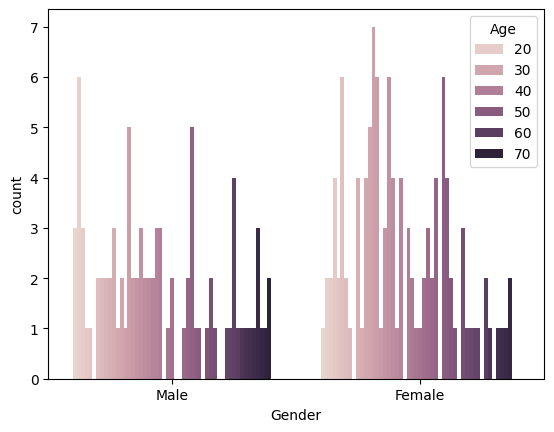

In [9]:
sns.countplot(x='Gender',hue='Age',data=df)

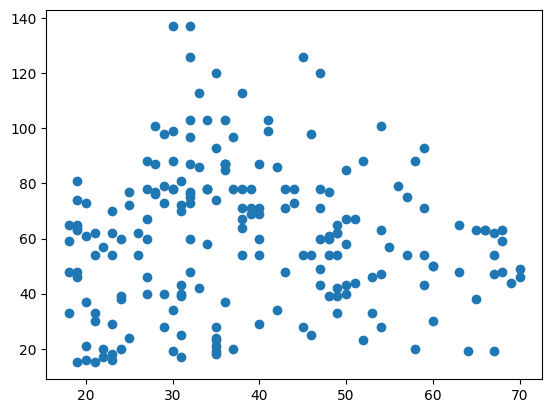

In [25]:
plt.scatter(df["Age"],df["income"])
plt.show()

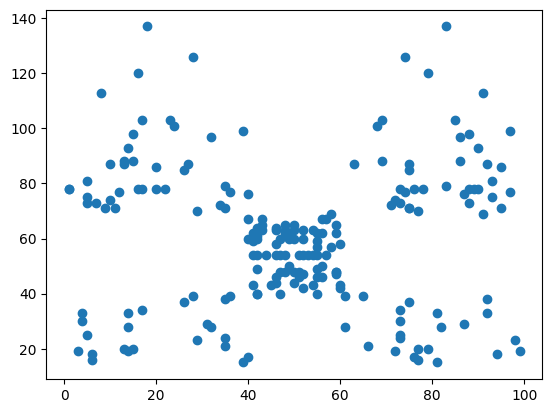

In [26]:
plt.scatter(df["score"],df["income"])
plt.show()

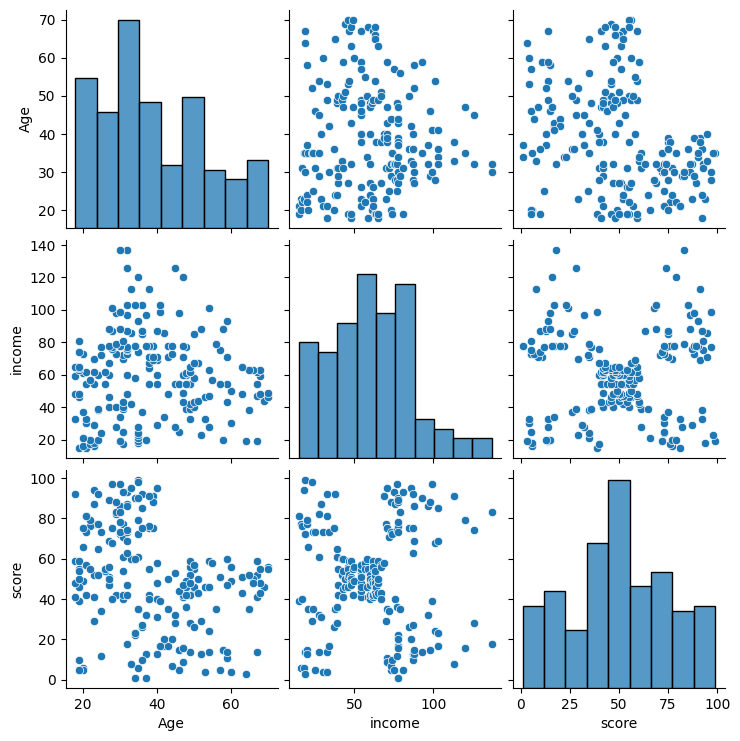

In [31]:
#Pairplot
sns.pairplot(df[["Age","income","score"]])


In [32]:
from sklearn.cluster import KMeans


In [34]:
#Elbow Method to find optimal number of clusters
wcss=[]
cluster=range(1,20)
for k in cluster:
    km1=KMeans(n_clusters=k)
    km1.fit(df[["income","score"]])
    wcss.append(km1.inertia_)

wcss
    

[269981.28,
 183069.17582751293,
 106348.37306211119,
 73679.78903948834,
 44448.45544793371,
 37558.92202302528,
 35758.868579246846,
 26189.003660625087,
 27445.806595076974,
 19704.123543147773,
 18439.52396711476,
 16473.93679286192,
 15132.982345914956,
 13986.975697577276,
 12778.42205454676,
 11557.32940268951,
 12203.131596619756,
 9894.654030609914,
 9273.642063492063]

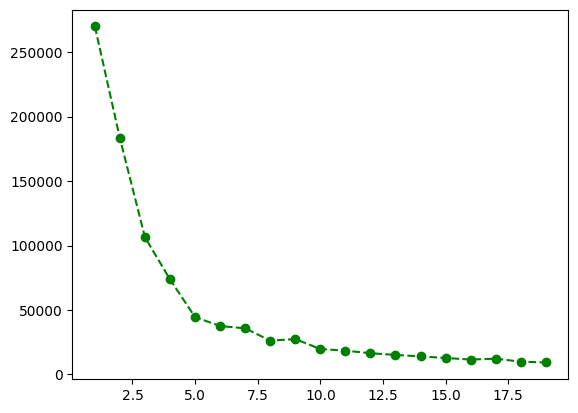

In [36]:
plt.plot(cluster,wcss,'go--')

In [37]:
from kneed import KneeLocator

In [40]:
kn=KneeLocator(cluster,wcss,curve="convex",direction="decreasing")
kn.knee

np.int64(5)

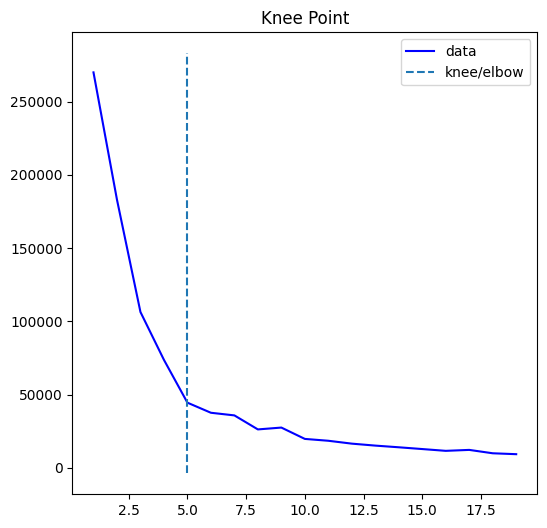

In [41]:
kn.plot_knee()

In [ ]:
#Trains the model where the cluster is 5

In [43]:
km2=KMeans(n_clusters=5)
predicted=km2.fit_predict(df[['income','score']])
predicted

array([3, 0, 3, 0, 3, 0, 3, 0, 3, 0, 3, 0, 3, 0, 3, 0, 3, 0, 3, 0, 3, 0,
       3, 0, 3, 0, 3, 0, 3, 0, 3, 0, 3, 0, 3, 0, 3, 0, 3, 0, 3, 0, 3, 1,
       3, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 2, 4, 2, 1, 2, 4, 2, 4, 2,
       1, 2, 4, 2, 4, 2, 4, 2, 4, 2, 1, 2, 4, 2, 4, 2, 4, 2, 4, 2, 4, 2,
       4, 2, 4, 2, 4, 2, 4, 2, 4, 2, 4, 2, 4, 2, 4, 2, 4, 2, 4, 2, 4, 2,
       4, 2, 4, 2, 4, 2, 4, 2, 4, 2, 4, 2, 4, 2, 4, 2, 4, 2, 4, 2, 4, 2,
       4, 2], dtype=int32)

In [44]:
df['initial_clusters']=predicted

In [45]:
df.head()

,Gender,Age,income,score,initial_clusters
0,Male,19,15,39,3
1,Male,21,15,81,0
2,Female,20,16,6,3
3,Female,23,16,77,0
4,Female,31,17,40,3


In [47]:
centers=km2.cluster_centers_
centers

array([[25.72727273, 79.36363636],
       [55.2962963 , 49.51851852],
       [86.53846154, 82.12820513],
       [26.30434783, 20.91304348],
       [88.2       , 17.11428571]])

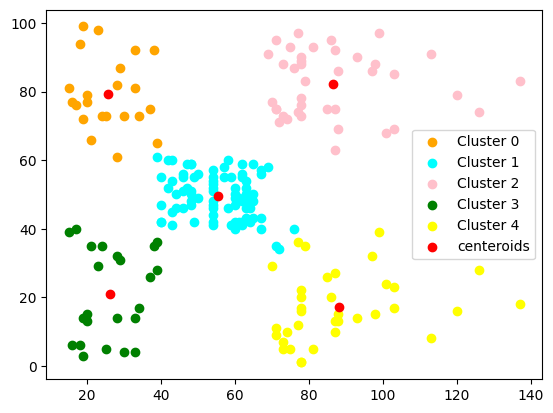

In [59]:
df0=df[df.initial_clusters == 0]
df1 = df[df.initial_clusters == 1]
df2 = df[df.initial_clusters == 2]
df3 = df[df.initial_clusters == 3]
df4 = df[df.initial_clusters == 4]

plt.scatter(df0['income'], df0['score'], color='orange',label='Cluster 0')
plt.scatter(df1['income'], df1['score'], color='cyan',label='Cluster 1')
plt.scatter(df2['income'], df2['score'], color='pink',label='Cluster 2')
plt.scatter(df3['income'], df3['score'], color='green',label='Cluster 3')
plt.scatter(df4['income'], df4['score'], color='yellow',label='Cluster 4')

#Centroids of each clusters
plt.scatter(centers[:,0],centers[:,1],color="red", label="centeroids")
plt.legend()

In [56]:
centers

array([[25.72727273, 79.36363636],
       [55.2962963 , 49.51851852],
       [86.53846154, 82.12820513],
       [26.30434783, 20.91304348],
       [88.2       , 17.11428571]])